In [1]:
from mt_rent_statement import *

### Load data

In [2]:
start='2024-12-01'
end='2024-12-31'
dfT=load_tenancies('all_tenancies.xls')
dfAll=load_data(start,end)
dfAll.head(3)

Reading file: C:\Work\Mat\property\data\property\checked\DEC2024_codedAndCategorised.xlsx


,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2024-12-01,60-83-71 00558156,-465.0,REPAIRS_AND_MAINTENANCE,Alhambra Road M Tucker SC,NaN,NaN,ServiceCharge,NaN
2024-12-01,60-83-71 00558156,-15.18,OTHER,Wilstead Pharmacy WILSTEAD PHARMACY,NaN,NaN,PersonalExpense,Pharmacy/Opticians/Dental
2024-12-01,60-83-71 00558156,525.0,REVENUE,Sean Connacher 321 rent,F3321LON,NaN,OurRent,NaN


### Rent Statement

In [11]:
paidinadvancelist = ['Nicole Byrne (17/05/2024)']
inarrearslist = []
dfRs=get_rent_statement(dfAll, dfT, start, end, inarrearslist, paidinadvancelist)
dfRs=dfRs.round(0)
#dfRs.sort_values(by=['Net'], ascending=False).style.apply(custom_style, axis=1)
#dfRs.sort_values(by=['Bills'], ascending=True).style.apply(custom_style, axis=1)
#dfRs.style.apply(custom_style, axis=1)
num_cols = dfRs.select_dtypes(include=["number"]).columns
dfRs.style.format({c: "{:.0f}" for c in num_cols}).apply(custom_style, axis=1)

,Tenant,Agent,Received,Bills,Mortgage,Net,Status
Property,,,,,,,
321 London Rd,,,0,0,0,0,
Flat 1 - 321 London Rd,Ruksana Akter Chowdhury (09/08/2023),0,725,-272,-463,-10,Paid
Flat 2 - 321 London Rd,Thomas Montgomery (08/03/2024-07/02/2026),0,750,0,-441,309,Paid
Flat 3 - 321 London Rd,Sean Connacher and Pete Davies (31/10/2024-31/03/2026),0,2100,0,-396,1704,Paid
Flat 4 - 321 London Rd,Chloe Freshney & Harry Aldingtons (31/01/2023),0,725,0,-463,262,Paid
169 Fawcett Rd,,,0,0,0,0,
Flat 1 - 169 Fawcett Rd,Tushar Dandekar and Madhura Dandekar (26/02/2024-30/07/2025),0,675,0,-417,258,Paid
Flat 2 - 169 Fawcett Rd,Matthew Granil (31/07/2024),0,775,0,-393,382,Paid
Flat 3 - 169 Fawcett Rd,August John (14/05/2022-31/03/2025),0,750,0,-443,307,Paid


Notes:
- F1 321 Chowdhury moved in day after Soumya Xaviour moved out, there were no Fox & Sons fees for this tenant
- F17 46 Sophie Bedford moved out end of July, Camilla Bailey & Michael Gregson move in 31/08/23
    - in September they paid 6 months in advance to 28/02/23
- 23B Shyni Bijumon & Bijumon Varghese moved in 03/09/23, there were no Fox & Sons fees for this tenant
- 23C Ancy Mathews & Mathews Jose moved in 08/10/23, there were no Fox & Sons fees for this tenant
- F7 8 Ben Kendall & Gabriella Nouvet-Aruaz moved in 08/09/23
- F22 46 Charlotte McLellan-Campbell and Jose Gongora Oliva moved in on 10/09/23
    - in October they paid 6 months in advance to 19/04/23 
- F3 321 Shubi Agarwal is moving out 27/12/23 - she asked to move out a before end of tenancy which was agreed to when we found new tenants (some found for 28/12/23)
- F11 1214 Betts died on 5th November, he paid to 25/11/23
- F14 1214 McIlwraith moved out 11/11/23
- F16 1618 Gradon was given notice because he had a guy living with him who was pissing on doorstep, he moved out 18/11/23. He had paid in advance, there was £2k to pay him back and some from Beals

Remarks:
- each 0.25% increase in rates causes an increase in costs of £750 - ideally we need rates back at 4.5% to pay £22500 p/m
- find out what happens when a business loans money to another and it is not repaid - ask Chatgpt
- things should improve in March - by then hopefully empties rented, paid in advance start to pay again in March

### Income/Expenditure per Property

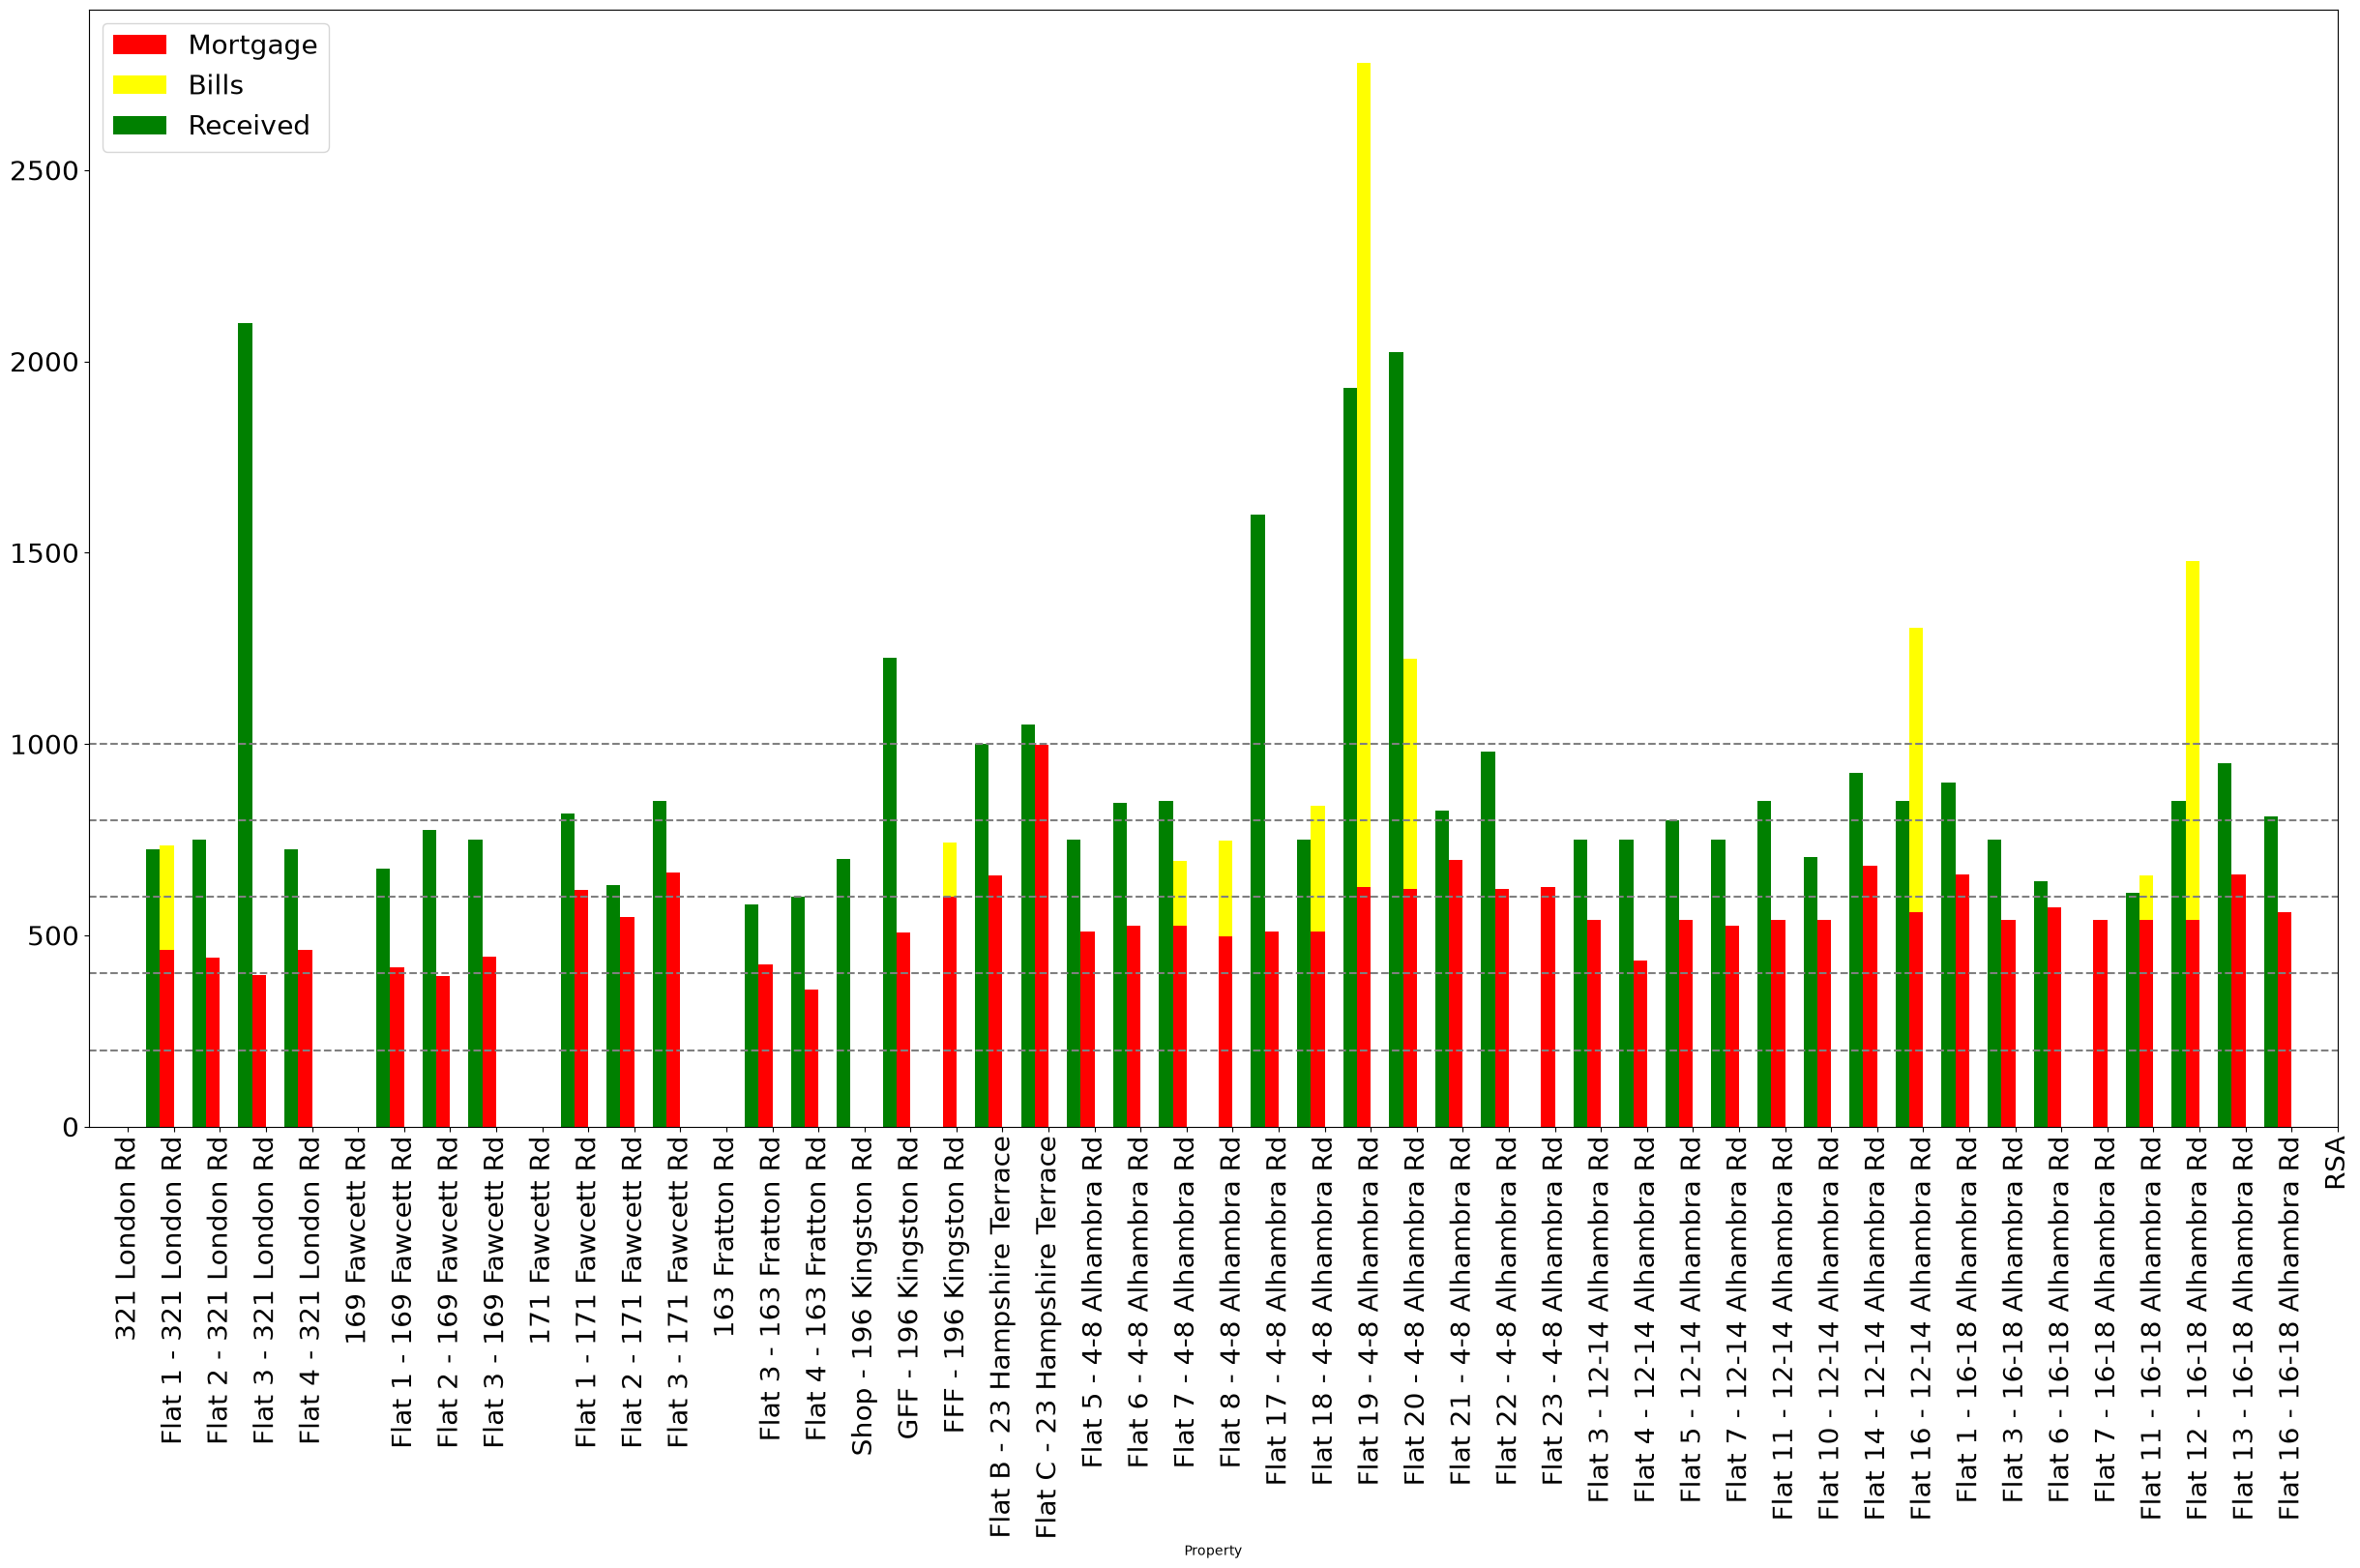

In [4]:
plot_income_expenditure_per_property(dfRs[:-1])

### Net Income Per Property

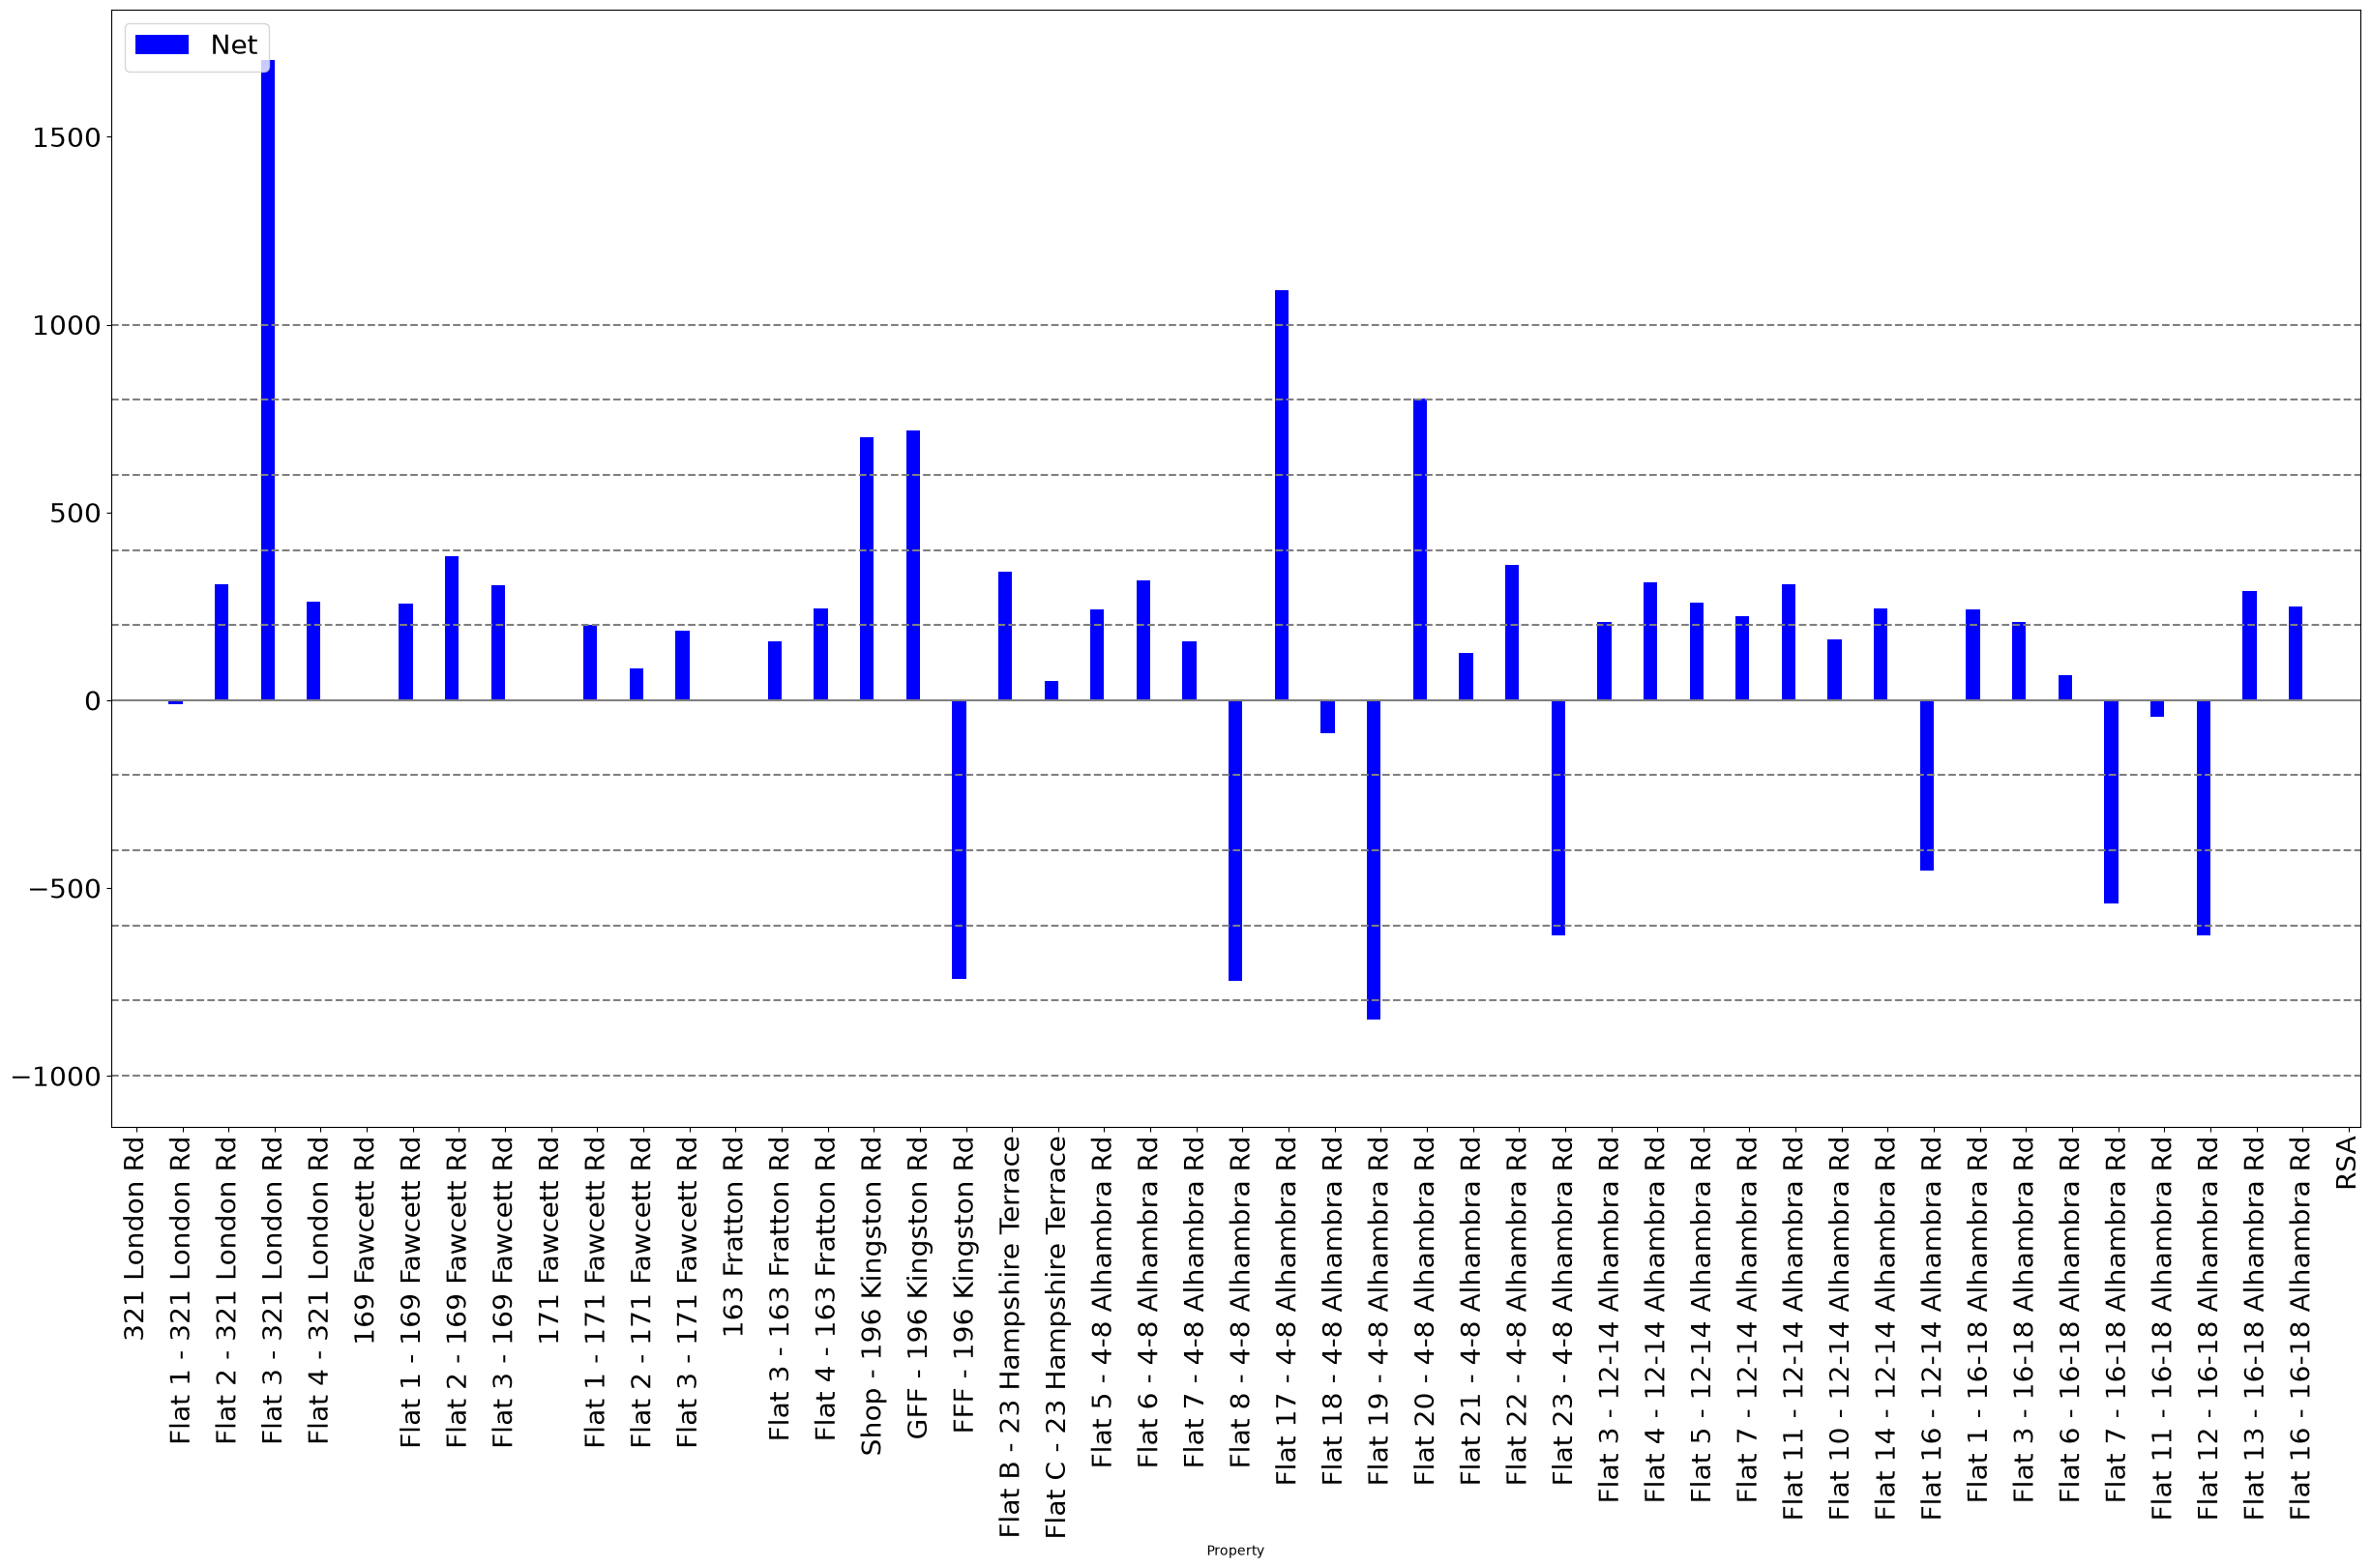

In [5]:
plot_net_income(dfRs[:-1])

### Personal Expenses


Total PersonalExpense: £2,558.72


<Axes: title={'center': 'PersonalExpense by Subcat (total £2,559)'}>

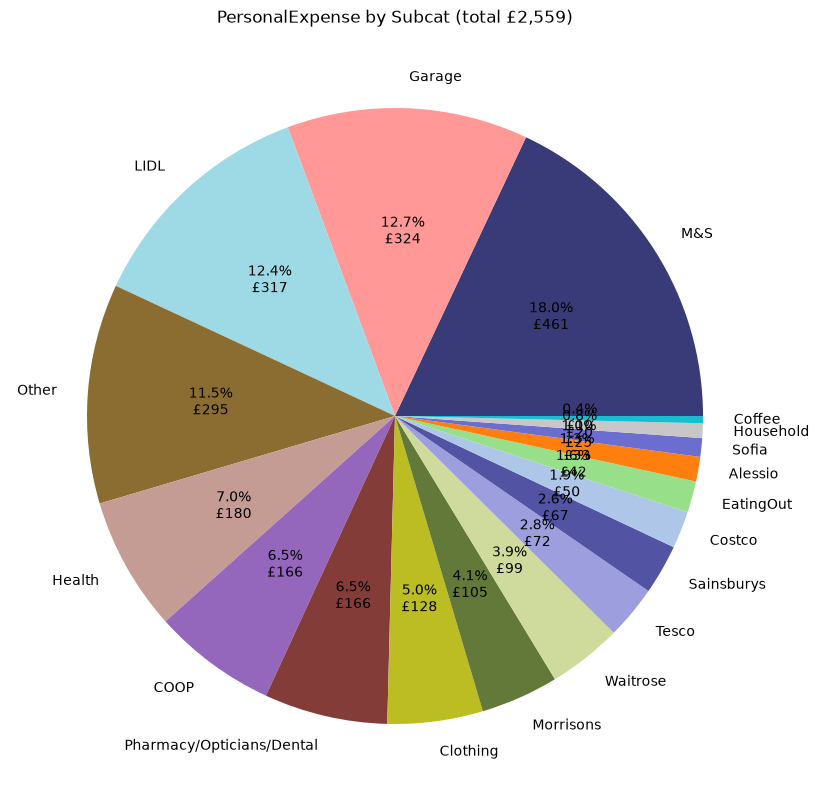

In [6]:
plot_personal_expense_by_subcat(dfAll, start, end)


### Accounts Check
Check Drawings against expenses

In [7]:
dfAll[(dfAll.Cat=='RegularPayment')|(dfAll.Cat=='PersonalExpense')|(dfAll.Cat=='Hilltop')|(dfAll.Cat=='HMRCDD')|(dfAll.Cat=='Drawings')|(dfAll.Cat=='SchoolFee')].groupby(['Cat']).sum()

,Account,Amount,Subcategory,Memo,Property,Description,Subcat
Cat,,,,,,,
Hilltop,20-74-09 60458872,-300.0,Standing Order,G & F VALENTINO M TUCKER STO,0,0,0
PersonalExpense,60-83-71 0055815660-83-71 0055815620-74-09 404...,-4696.37,OTHERFOOD_AND_DRINKFunds TransferContactless C...,Wilstead Pharmacy WILSTEAD PHARMACY Tesco TESC...,0,For RoccoCosmeticsChristmas moneyChristmas mon...,Pharmacy/Opticians/DentalTescoAlessioEatingOut...
RegularPayment,20-53-97 3072869120-74-09 6045887220-74-09 604...,-1292.99,Direct DebitDirect DebitDirect DebitStanding O...,L G INSURANCE MI 0114399215-241202 DDRPIC...,0,0,IVCarSFLoan


In [8]:
dfAll.groupby(['Account','Cat']).sum().style.apply(custom_style_accounts_cat, axis=1)

#### Mortgage check
Check mortgages refunded from business account

In [9]:
dfMtg=dfAll[((dfAll.Cat=='Mortgage')|(dfAll.Cat=='MortgageRefund'))&(dfAll.Account!='60-83-71 00558156')].groupby(['Account','Cat']).Amount.sum()
dfMtg=dfMtg.reset_index().pivot('Account','Cat')
dfMtg.columns=dfMtg.columns.get_level_values(1)
if('MortgageRefund' not in dfMtg.columns):
    dfMtg['MortgageRefund']=0
dfMtg['Diff']=dfMtg.Mortgage + dfMtg.MortgageRefund
dfMtg

TypeError: DataFrame.pivot() takes 1 positional argument but 3 were given

In [ ]:
dfMtg['Diff'].sum()

#### Rent check
Rents going to wrong account

In [ ]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')]

In [ ]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')].groupby(['Cat']).sum()

#### Property expense check
Property expenses and service charges taken from 3072 or 6045

In [ ]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')]

In [ ]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')].groupby(['Cat']).sum()

In [ ]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')]

In [ ]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')].groupby(['Cat']).sum()